# Figure 3 — Stabilizing the scheme by rate averaging

Pena, Vellmer, Bernardi, Roque & Lindner (2018), *Self-Consistent Scheme for Spike-Train Power Spectra in Heterogeneous Sparse Networks*, Front. Comput. Neurosci. 12:9, doi:10.3389/fncom.2018.00009.

**Caption (paper):** Stabilization of the iterative scheme by averaging over previous generations
(inhibition-dominated regime). Firing rate of the scheme (blue) vs the recurrent network (red, ν = 9.1 Hz).
g = 5.5, J = 0.2 mV, τs = 10 ms, γ = 0.25, RI_ext = 30 mV.
(A) no averaging, (B) average over the past two generations, (C) average over all past generations,
(D) ν_out,i(ν_in) after i iterations of the averaging procedure, using the Brunel & Sergi (1998) rate for
synaptically filtered white noise; the fixed point is unstable because |dν_out/dν_in| > 1.

**What the published figure shows** (read from the PDF, p. 7): generations **0–10** on the x-axis;
every panel starts at **13 Hz** in generation 0; Panel D is five stacked panels (ν_out,0 … ν_out,4, axes 0–20 Hz)
with a cobweb starting from ν_in = 13 Hz. The method text (Section 2.4.2) uses 10,000 trials per generation.

**Conventions (inferred from the published curves; they reproduce A–C generation by generation):**
- Generation 0 is the starting rate r₀ = 13 Hz with a flat (white-noise) spectrum; it is not simulated.
- Generation n ≥ 1: mean input from the averaged rate ν̂ₙ₋₁ (Eq. 12), noise from the previous generation's output spectrum (Eqs. 13–14).
- Plotted quantity: the averaged rate ν̂ₙ (for A, ν̂ₙ = rₙ).
- **B:** ν̂ₙ = (ν̂ₙ₋₁ + rₙ)/2. The literal reading (rₙ₋₁ + rₙ)/2 is linearly unstable here, because
  the rate map has slope −2.56 at its fixed point and two-sample averaging needs slope > −2. It ends in a 0/63 Hz cycle,
  which is why earlier versions of this notebook could not reproduce B. Set `B_MODE = "last2"` to see it.
- **C:** ν̂ₙ = mean(r₀ … rₙ), including generation 0.
- `dt = 0.1 ms` (not stated in the paper), Euler integration, τm = 20 ms.
- The red network rate is the caption value (9.1 Hz); no network is simulated here.

Implementation: [`pena_scheme.py`](pena_scheme.py) (`run_scheme`, `averaged_map`).

In [1]:
from pathlib import Path
import sys, json, time

import numpy as np
import matplotlib.pyplot as plt

# Locate 05_Pena2018_Replication whether launched from the repo root or this folder.
HERE = Path.cwd()
if not (HERE / "pena2018_params.py").exists():
    HERE = HERE / "05_Pena2018_Replication"
sys.path.insert(0, str(HERE))

from pena2018_params import params_for
import pena_scheme as ps
RESULTS = HERE / "results"; FIGURES = HERE / "figures"
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)

In [2]:
P = params_for(3)

# --- run controls -----------------------------------------------------------
RUN_SCHEME = True          # False: only load saved results
N_TRIALS = 10_000          # paper value (Section 2.4.2); ~3-4 min per panel on 2 CPUs
N_GENERATIONS = 10         # generations shown in the published Fig 3
NU0 = 13.0                 # generation-0 rate (Hz), read from the published figure
SEED = 3
B_MODE = 2                 # 2: nu_hat_n = (nu_hat_{n-1} + r_n)/2 (matches paper); "last2": (r_{n-1} + r_n)/2
NETWORK_RATE = P["target_network_rate_Hz"]  # 9.1 Hz from the caption

MODES = {"A": 1, "B": B_MODE, "C": None}   # see run_scheme docstring

# Values read off the published Fig 3 (approximate, +-0.2 Hz), for comparison only.
PAPER = {"A": [13, 2, 51, 0, 63, 0, 63, 0, 63, 0, 63],
         "B": [13.1, 7.4, 8.4, 9.7, 8.6, 9.4, 9.0, 9.2, 9.1, 9.1, 9.1],
         "C": [13.0, 7.4, 8.1, 9.1, 9.3, 9.2, 9.1, 9.1, 9.1, 9.1, 9.1]}
{k: P[k] for k in ["g", "J", "tau_s", "RI_ext", "tau_m", "V_th", "V_r", "tau_ref",
                   "C_E", "C_I", "dt", "T_window", "T_transient"]}

{'g': 5.5,
 'J': 0.2,
 'tau_s': 10.0,
 'RI_ext': 30.0,
 'tau_m': 20.0,
 'V_th': 20.0,
 'V_r': 10.0,
 'tau_ref': 2.0,
 'C_E': 1000,
 'C_I': 250,
 'dt': 0.1,
 'T_window': 2000.0,
 'T_transient': 1000.0}

## Scheme runs (panels A–C)
Each panel is saved to `results/` and reloaded on rerun.

In [3]:
def run_id(label, avg):
    a = "all" if avg is None else avg
    return f"figure03v2_{label}_avg{a}_trials{N_TRIALS}_gen{N_GENERATIONS}_nu0{NU0:g}_seed{SEED}"

runs = {}
for label, avg in MODES.items():
    rid = run_id(label, avg)
    npz, meta = RESULTS / f"{rid}.npz", RESULTS / f"{rid}.json"
    if npz.exists():
        runs[label] = dict(np.load(npz))
        print(f"{label}: loaded {npz.name}")
        continue
    if not RUN_SCHEME:
        print(f"{label}: no saved result and RUN_SCHEME = False"); continue
    print(f"--- panel {label}: average = {avg!r}")
    t0 = time.time()
    out = ps.run_scheme(P, N_GENERATIONS, N_TRIALS, avg, nu0=NU0, seed=SEED)
    np.savez_compressed(npz, **out)
    meta.write_text(json.dumps({"figure": 3, "panel": label, "average": avg,
        "n_trials": N_TRIALS, "n_generations": N_GENERATIONS, "nu0": NU0, "seed": SEED,
        "params": P, "runtime_s": time.time() - t0}, indent=2, default=str))
    runs[label] = out

A: loaded figure03v2_A_avg1_trials10000_gen10_nu013_seed3.npz
B: loaded figure03v2_B_avg2_trials10000_gen10_nu013_seed3.npz
C: loaded figure03v2_C_avgall_trials10000_gen10_nu013_seed3.npz


## Rate map (panel D)
Analytical Brunel & Sergi (1998) rate; ν_out,i is the output after i rounds, r_(k+1) = ν_out(mean(r_0..r_k)), r_0 = ν_in.

In [4]:
nu_in = np.linspace(0.05, 20, 400)
N_ROUNDS = 5
rate_map = np.array([[ps.averaged_map(v, i, P) for v in nu_in] for i in range(N_ROUNDS)])
from scipy.optimize import brentq
fp = brentq(lambda v: ps.nu_out_white(v, P) - v, 1, 20)
h = 1e-3
slope = (ps.nu_out_white(fp + h, P) - ps.nu_out_white(fp - h, P)) / (2 * h)
print(f"fixed point of nu_out(nu_in): {fp:.2f} Hz, slope {slope:.2f} (network: {NETWORK_RATE} Hz)")
print(f"two-sample averaging (r_(n-1)+r_n)/2 is stable only if slope > -2 -> {'stable' if slope > -2 else 'UNSTABLE'}")

fixed point of nu_out(nu_in): 8.72 Hz, slope -2.56 (network: 9.1 Hz)
two-sample averaging (r_(n-1)+r_n)/2 is stable only if slope > -2 -> UNSTABLE


## Figure

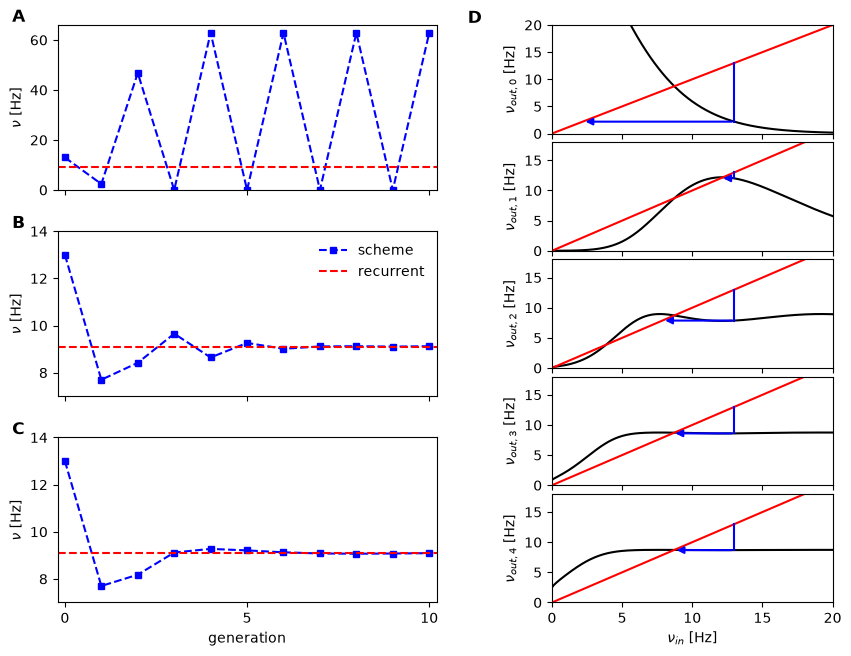

In [5]:
fig = plt.figure(figsize=(10, 7.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1.35, 1], wspace=0.35)
left = gs[0].subgridspec(3, 1, hspace=0.25)
right = gs[1].subgridspec(N_ROUNDS, 1, hspace=0.08)
ylims = {"A": (0, 66), "B": (7, 14), "C": (7, 14)}
for k, label in enumerate("ABC"):
    ax = fig.add_subplot(left[k])
    if label in runs:
        y = runs[label]["nu_hat"]
        ax.plot(np.arange(len(y)), y, "s--", color="blue", ms=5, label="scheme")
    ax.axhline(NETWORK_RATE, color="red", ls="--", label="recurrent")
    ax.set(xlim=(-0.2, N_GENERATIONS + 0.2), ylim=ylims[label], ylabel=r"$\nu$ [Hz]")
    ax.text(-0.12, 1.02, label, transform=ax.transAxes, fontweight="bold", fontsize=12)
    if label == "B":
        ax.legend(frameon=False, loc="upper right")
    if label == "C":
        ax.set_xlabel("generation")
    else:
        ax.tick_params(labelbottom=False)
    ax.set_xticks([0, 5, 10])

for i in range(N_ROUNDS):
    ax = fig.add_subplot(right[i])
    ax.plot(nu_in, rate_map[i], "k", lw=1.5)
    ax.plot([0, 20], [0, 20], "r", lw=1.5)
    y13 = ps.averaged_map(NU0, i, P)               # cobweb from nu_in = 13 Hz
    ax.plot([NU0, NU0], [NU0, y13], "b", lw=1.5)
    ax.annotate("", xy=(y13, y13), xytext=(NU0, y13),
                arrowprops=dict(arrowstyle="-|>", color="b", lw=1.5))
    ax.set(xlim=(0, 20), ylim=(0, 20 if i == 0 else 18), ylabel=rf"$\nu_{{out,{i}}}$ [Hz]")
    ax.set_yticks([0, 5, 10, 15] + ([20] if i == 0 else []))
    if i == 0:
        ax.text(-0.3, 1.02, "D", transform=ax.transAxes, fontweight="bold", fontsize=12)
    if i < N_ROUNDS - 1:
        ax.tick_params(labelbottom=False)
    else:
        ax.set_xlabel(r"$\nu_{in}$ [Hz]")

fig.savefig(FIGURES / "figure03_rate_averaging.png", dpi=200, bbox_inches="tight")
fig.savefig(FIGURES / "figure03_rate_averaging.pdf", bbox_inches="tight")
plt.show()

## Comparison with the published values

In [6]:
print("gen  " + "".join(f"{g:>7d}" for g in range(N_GENERATIONS + 1)))
for label in "ABC":
    if label not in runs: continue
    ours = runs[label]["nu_hat"]
    print(f"{label} ours  " + "".join(f"{v:7.2f}" for v in ours))
    print(f"{label} paper " + "".join(f"{v:7.1f}" for v in PAPER[label]))
for label in "BC":
    if label in runs:
        tail = runs[label]["nu_hat"][-4:]
        print(f"panel {label}: generations 7-10 mean = {tail.mean():.2f} Hz (network {NETWORK_RATE} Hz)")

gen        0      1      2      3      4      5      6      7      8      9     10
A ours    13.00   2.40  46.79   0.00  62.86   0.00  62.86   0.00  62.86   0.00  62.86
A paper    13.0    2.0   51.0    0.0   63.0    0.0   63.0    0.0   63.0    0.0   63.0
B ours    13.00   7.70   8.42   9.65   8.65   9.26   9.01   9.11   9.12   9.11   9.12
B paper    13.1    7.4    8.4    9.7    8.6    9.4    9.0    9.2    9.1    9.1    9.1
C ours    13.00   7.70   8.18   9.12   9.27   9.21   9.13   9.08   9.07   9.08   9.09
C paper    13.0    7.4    8.1    9.1    9.3    9.2    9.1    9.1    9.1    9.1    9.1
panel B: generations 7-10 mean = 9.12 Hz (network 9.1 Hz)
panel C: generations 7-10 mean = 9.08 Hz (network 9.1 Hz)


## Notes

- The red line is the caption's network rate; Pena et al. ran the recurrent network with N_E = 100,000, which is not simulated here.
- Panel D uses the analytical white-noise rate, so its fixed point (≈ 8.7 Hz) is a little lower than the scheme's colored-noise rate (≈ 9.1 Hz).